# Customer Churn & CLV — Modeling

## Objective

In this notebook I train and compare three approaches to predict which customers will churn in the next 90 days:

1. **Baseline – recency rule:** "the more days since the last purchase, the higher the risk". This is what a business would do without Machine Learning. A model is only useful if it beats this rule.
2. **Logistic Regression:** a simple and interpretable model.
3. **LightGBM:** a gradient boosting model that can capture non-linear relationships.

Since this is a **classification** problem (my previous projects were regression), the metrics are different:

- **ROC-AUC:** how well the model ranks churners above non-churners (0.5 = random, 1 = perfect).
- **PR-AUC:** precision vs recall, more informative when the classes are not balanced.
- **Lift @ top 10%:** how many times more churners there are in the 10% of customers with the highest risk compared with picking customers at random.
- **Brier score:** quality of the probabilities (lower is better).

In [1]:
# Import all the libraries necessary for this section
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import lightgbm as lgb
import shap

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load the churn dataset
DATA_PATH = Path("../data/processed/churn_dataset.csv")

churn_df = pd.read_csv(DATA_PATH)

churn_df.shape

(17675, 20)

In [3]:
churn_df.head()

,CustomerID,recency_days,frequency,monetary,avg_order_value,avg_items_per_order,days_since_first_order,avg_days_between_orders,frequency_30d,monetary_30d,frequency_90d,monetary_90d,spend_trend,n_products,is_uk,return_rate,peak_season_ahead,churn,snapshot,set
0,12346,100,1,27.05,27.050000,5.000000,100,NaN,0.0,0.00,0.0,0.00,-1.000000,5,1,0.000000,0,0,2010-06-11,train
1,12349,42,1,1068.52,1068.520000,473.000000,42,NaN,0.0,0.00,1.0,1068.52,1.000000,46,0,0.000000,0,1,2010-06-11,train
2,12355,20,1,488.21,488.210000,303.000000,20,NaN,1.0,488.21,1.0,488.21,1.000000,22,0,0.000000,0,1,2010-06-11,train
3,12358,3,1,268.10,268.100000,281.000000,3,NaN,1.0,268.10,1.0,268.10,1.000000,17,0,0.000000,0,1,2010-06-11,train
4,12359,79,3,761.54,253.846667,126.666667,176,47.5,0.0,0.00,1.0,345.60,-0.092365,34,0,0.123434,0,0,2010-06-11,train


## Features and sets

In [4]:
# Define the features and target variable for the model
features = [
    "recency_days",
    "frequency",
    "monetary",
    "avg_order_value",
    "avg_items_per_order",
    "days_since_first_order",
    "avg_days_between_orders",
    "frequency_30d",
    "monetary_30d",
    "frequency_90d",
    "monetary_90d",
    "spend_trend",
    "n_products",
    "is_uk",
    "return_rate",
    "peak_season_ahead"
]

target = "churn"

In [5]:
# Split the dataset by time using the 'set' column created in the previous notebook
train_df = churn_df[churn_df["set"] == "train"]
valid_df = churn_df[churn_df["set"] == "validation"]
test_df = churn_df[churn_df["set"] == "test"]

X_train, y_train = train_df[features], train_df[target]
X_valid, y_valid = valid_df[features], valid_df[target]
X_test, y_test = test_df[features], test_df[target]

print(f"X_train shape: {X_train.shape} | churn rate: {y_train.mean():.1%}")
print(f"X_valid shape: {X_valid.shape} | churn rate: {y_valid.mean():.1%}")
print(f"X_test shape:  {X_test.shape} | churn rate: {y_test.mean():.1%}")

X_train shape: (12260, 16) | churn rate: 53.6%
X_valid shape: (2640, 16) | churn rate: 50.5%
X_test shape:  (2775, 16) | churn rate: 38.5%


In [6]:
# Create a function to evaluate a model with the four metrics
def evaluate(y_true, y_score, is_probability=True):

    # Lift: churn rate in the top 10% riskiest customers vs the average churn rate
    top_10 = np.argsort(-y_score)[: int(len(y_true) * 0.10)]
    lift = y_true.values[top_10].mean() / y_true.mean()

    return {
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "PR-AUC": average_precision_score(y_true, y_score),
        "Lift@10%": lift,
        "Brier": brier_score_loss(y_true, y_score) if is_probability else np.nan,
    }

## Baseline: Recency rule

In [7]:
# The score of the baseline is simply the number of days since the last order
baseline_valid = evaluate(y_valid, X_valid["recency_days"].values, is_probability=False)
baseline_test = evaluate(y_test, X_test["recency_days"].values, is_probability=False)

print("Recency rule - validation:", {k: round(v, 3) for k, v in baseline_valid.items()})
print("Recency rule - test:      ", {k: round(v, 3) for k, v in baseline_test.items()})

Recency rule - validation: {'ROC-AUC': 0.652, 'PR-AUC': 0.632, 'Lift@10%': np.float64(1.364), 'Brier': nan}
Recency rule - test:       {'ROC-AUC': 0.658, 'PR-AUC': 0.534, 'Lift@10%': np.float64(1.585), 'Brier': nan}


## Logistic Regression Model

Logistic Regression needs some preprocessing:

- **Log transformation** of the money and count variables, because they are very skewed.
- **Imputation** of the missing values (`avg_days_between_orders`) with the median.
- **Scaling**, so all the variables have the same scale.

I put everything inside a `Pipeline` so the preprocessing is learned only with the training data.

In [8]:
# Define the skewed variables that will be log-transformed
skewed_features = ["monetary", "monetary_30d", "monetary_90d", "avg_order_value", "avg_items_per_order", "frequency", "n_products"]


def log_transform(X):
    X = X.copy()
    X[skewed_features] = np.log1p(X[skewed_features].clip(lower=0))
    return X


# Define the Logistic Regression pipeline
model_logistic = Pipeline(
    steps=[
        ("log", FunctionTransformer(log_transform)),
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000))
    ]
)

In [9]:
# Fit the Logistic Regression model on the training data
model_logistic.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('log', ...), ('imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['recency_days','frequency','monetary',...,'is_uk','return_rate', 'peak_season_ahead']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function log...x7fc0050045e0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [10]:
# Predict the churn probability on the validation and test sets
proba_valid_lr = model_logistic.predict_proba(X_valid)[:, 1]
proba_test_lr = model_logistic.predict_proba(X_test)[:, 1]

logistic_valid = evaluate(y_valid, proba_valid_lr)
logistic_test = evaluate(y_test, proba_test_lr)

print("Logistic Regression - validation:", {k: round(v, 3) for k, v in logistic_valid.items()})
print("Logistic Regression - test:      ", {k: round(v, 3) for k, v in logistic_test.items()})

Logistic Regression - validation: {'ROC-AUC': 0.753, 'PR-AUC': 0.715, 'Lift@10%': np.float64(1.522), 'Brier': 0.208}
Logistic Regression - test:       {'ROC-AUC': 0.731, 'PR-AUC': 0.586, 'Lift@10%': np.float64(1.745), 'Brier': 0.2}


## LightGBM Model

LightGBM builds many small decision trees in sequence, each one correcting the errors of the previous ones. It handles missing values by itself and doesn't need scaling.

To avoid overfitting I use small trees, a low learning rate and **early stopping**: the model stops adding trees when the ROC-AUC on the validation set stops improving.

In [11]:
# Define the LightGBM model
model_lgbm = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.02,
    num_leaves=15,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1
)

In [12]:
# Fit the LightGBM model with early stopping on the validation set
model_lgbm.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="auc",
    callbacks=[lgb.early_stopping(50, verbose=False)]
)

print("Best iteration:", model_lgbm.best_iteration_)

/usr/local/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Best iteration: 141


In [13]:
# Predict the churn probability on the validation and test sets
proba_valid_lgbm = model_lgbm.predict_proba(X_valid)[:, 1]
proba_test_lgbm = model_lgbm.predict_proba(X_test)[:, 1]

lgbm_valid = evaluate(y_valid, proba_valid_lgbm)
lgbm_test = evaluate(y_test, proba_test_lgbm)

print("LightGBM - validation:", {k: round(v, 3) for k, v in lgbm_valid.items()})
print("LightGBM - test:      ", {k: round(v, 3) for k, v in lgbm_test.items()})

LightGBM - validation: {'ROC-AUC': 0.757, 'PR-AUC': 0.712, 'Lift@10%': np.float64(1.514), 'Brier': 0.206}
LightGBM - test:       {'ROC-AUC': 0.733, 'PR-AUC': 0.59, 'Lift@10%': np.float64(1.763), 'Brier': 0.2}


## Comparison Table

In [14]:
model_results = pd.DataFrame(
    [baseline_test, logistic_test, lgbm_test],
    index=["Recency rule", "Logistic Regression", "LightGBM"]
).round(3)

model_results

,ROC-AUC,PR-AUC,Lift@10%,Brier
Recency rule,0.658,0.534,1.585,NaN
Logistic Regression,0.731,0.586,1.745,0.2
LightGBM,0.733,0.590,1.763,0.2


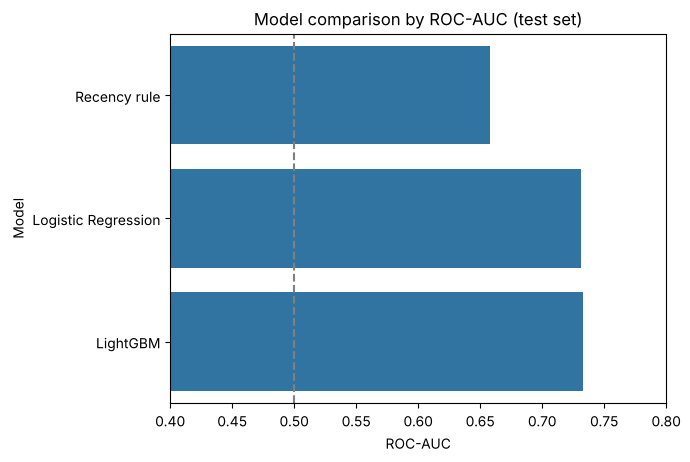

In [15]:
sns.barplot(
    data=model_results.reset_index(),
    x="ROC-AUC",
    y="index"
)

plt.axvline(0.5, color="grey", linestyle="--")
plt.title("Model comparison by ROC-AUC (test set)")
plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.xlim(0.4, 0.8)
plt.show()

### Model Comparison

- Both Machine Learning models clearly beat the recency rule (ROC-AUC 0.73 vs 0.66), so the extra features add real information.
- **Logistic Regression and LightGBM perform almost the same.** This was a surprise for me: it means that the relationship between the features and churn is quite simple (more orders = less churn), and a linear model already captures most of it.
- I choose **LightGBM** as the final model because it is slightly better on the test set and, as shown below, its probabilities are well calibrated. But in a real project, Logistic Regression would also be a good option because it is easier to explain.
- The results on validation and test are similar, so there is no sign of overfitting.

## Cumulative Gains

If we contact the customers ordered from highest to lowest risk, which share of all the churners do we find?

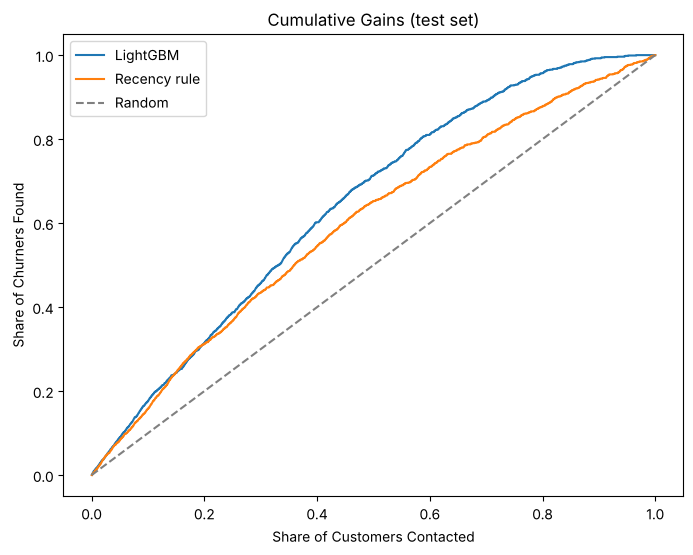

In [16]:
# Calculate the cumulative share of churners found when contacting customers by risk
def gains_curve(y_true, y_score):
    order = np.argsort(-y_score)
    churners_found = np.cumsum(y_true.values[order]) / y_true.sum()
    customers_contacted = np.arange(1, len(y_true) + 1) / len(y_true)
    return customers_contacted, churners_found


plt.figure(figsize=(8, 6))

x, y = gains_curve(y_test, proba_test_lgbm)
plt.plot(x, y, label="LightGBM")

x, y = gains_curve(y_test, X_test["recency_days"].values)
plt.plot(x, y, label="Recency rule")

plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random")

plt.title("Cumulative Gains (test set)")
plt.xlabel("Share of Customers Contacted")
plt.ylabel("Share of Churners Found")
plt.legend()
plt.show()

## Calibration

In the business stage I will multiply the churn probability by the value of each customer, so the probabilities must be realistic: if the model says 30%, around 30% of those customers should churn.

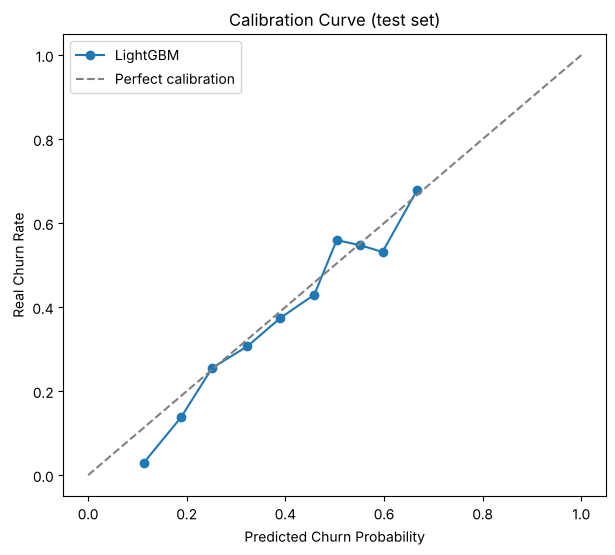

Average predicted churn: 40.4%
Real churn rate:         38.5%


In [17]:
# Compare the predicted probabilities with the real churn rate
fraction_churn, mean_predicted = calibration_curve(y_test, proba_test_lgbm, n_bins=10, strategy="quantile")

plt.figure(figsize=(7, 6))

plt.plot(mean_predicted, fraction_churn, marker="o", label="LightGBM")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")

plt.title("Calibration Curve (test set)")
plt.xlabel("Predicted Churn Probability")
plt.ylabel("Real Churn Rate")
plt.legend()
plt.show()

print(f"Average predicted churn: {proba_test_lgbm.mean():.1%}")
print(f"Real churn rate:         {y_test.mean():.1%}")

### Key Findings

- Contacting the 40% of customers with the highest risk finds around 60% of all the churners.
- The calibration curve follows the diagonal and the average prediction (40.4%) is close to the real churn rate (38.5%). The probabilities can be used as real probabilities.

## Model Interpretation (SHAP)

SHAP explains each prediction as the contribution of each feature. A positive SHAP value pushes the customer towards churn and a negative value pushes towards staying.

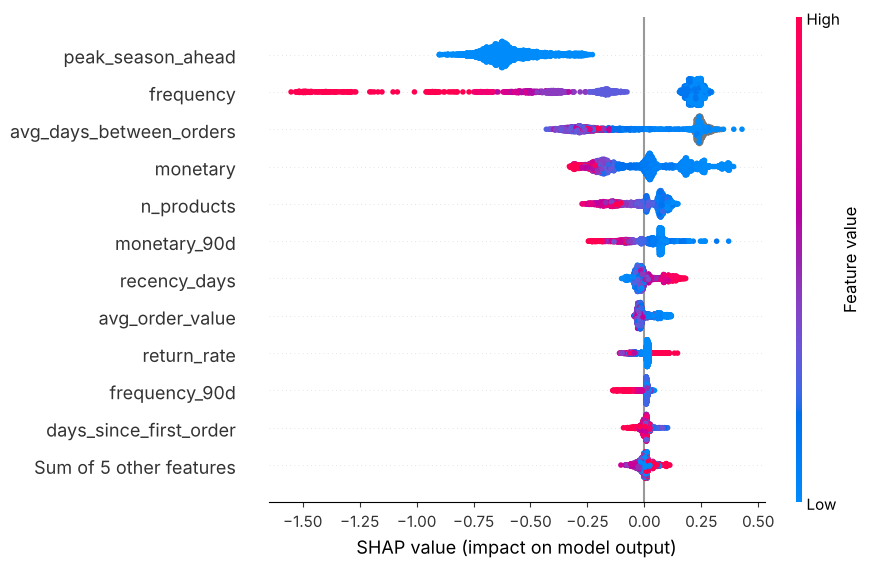

In [18]:
# Calculate the SHAP values of the test set
explainer = shap.TreeExplainer(model_lgbm)
shap_values = explainer(X_test)

# Some versions of shap return one set of values per class
if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

shap.plots.beeswarm(shap_values, max_display=12)

### Model Interpretation

- **Seasonality** (`peak_season_ahead`) has the biggest effect: when the Q4 peak is coming, the risk decreases for everyone.
- **Frequency** is the strongest protection at customer level: customers with many orders rarely churn.
- **Customers with only one order** (`avg_days_between_orders` empty, grey points) have a higher risk.
- High **monetary** value and many different **products** reduce the risk.
- A high **recency** and a high **return rate** increase the risk.

As in my previous project, these results describe how the model behaves and **should not be interpreted as causality**.

## Final Model Export

I save the final model and the test predictions, which will be used in the business notebook and in the Streamlit application.

In [19]:
# Save the final LightGBM model
MODEL_PATH = Path("../models/churn_lgbm_model.pkl")
MODEL_PATH.parent.mkdir(exist_ok=True)

joblib.dump(model_lgbm, MODEL_PATH)

print("Model saved successfully.")

Model saved successfully.


In [20]:
# Save the test set with the predicted churn probability
test_scored = test_df[["CustomerID", "recency_days", "frequency", "monetary", "churn"]].copy()
test_scored["churn_probability"] = proba_test_lgbm

test_scored.to_csv("../data/processed/test_scored.csv", index=False)

test_scored.head()

,CustomerID,recency_days,frequency,monetary,churn,churn_probability
14900,12347,37,3,1603.68,0,0.226468
14901,12348,156,1,327.00,0,0.576627
14902,12352,170,2,240.66,0,0.612247
14903,12353,112,1,89.00,1,0.701332
14904,12354,140,1,1079.40,1,0.490243


## Conclusions

- The final model is **LightGBM**, with a **ROC-AUC of 0.733** on the test set (vs 0.658 for the recency rule) and a **lift of 1.76** in the 10% riskiest customers.
- Logistic Regression performs almost the same (0.731), which shows that good features are more important than a complex algorithm.
- The probabilities are well calibrated, so they can be combined with the value of each customer.
- An AUC of 0.73 is realistic for churn: some customers leave for reasons that are not visible in the transactions (a competitor, a shop closing...).